> Paths here point at a flat working folder (`generated_sequences/`, `dna/`,
> `pdbqt/`, `output/`, `template/`), not at this repo's layout. The folders under
> `data/` use the same names, so copy them into one folder to re-run. See
> `docs/RERUN.md`.
>
> Code cells and stored outputs are as they were run. Only markdown was fixed
> where it contradicted the code.


# Stage 2 — Pre-filtering and Scoring

**Project:** DNA-based electrochemical sensor for IQS (quorum sensing molecule)  
**Input:** `./generated_sequences/stage1_candidates.csv` (10,000 sequences from Stage 1)  
**Output:** `./generated_sequences/stage2_filtered.csv` (top 2,000 sequences)  

---
### What this notebook does:
1. Loads Stage 1 sequences from CSV
2. Calculates **Score A** — Thermodynamic stability (Tm, Wallace Rule)
3. Calculates **Score B** — IQS interaction potential (π-stacking + H-bond + position weighting)
4. Combines into one **Total Score** and ranks all 10,000 sequences
5. Keeps top candidates and saves to CSV
6. Shows plots and summary statistics

---
### Scoring Logic:
```
Total Score = (0.40 × Tm Score) + (0.60 × IQS Score)
```
- **Tm Score (40%)** — based on Wallace Rule (1979). Rewards sequences with Tm in the optimal range for sensor use.
- **IQS Score (60%)** — based on IQS molecular structure (benzene ring + carbonyl + amine). Rewards π-stacking potential and H-bond potential in the groove.

## Cell 1 — Import Libraries

In [1]:
import os
import math
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

print("Libraries loaded successfully.")

Libraries loaded successfully.


## Cell 2 — Settings (Edit These If Needed)

In [2]:
# ── INPUT / OUTPUT ─────────────────────────────────────────────
INPUT_FILE    = os.path.join("generated_sequences", "stage1_candidates.csv")
OUTPUT_FILE   = os.path.join("generated_sequences", "stage2_filtered.csv")

# ── HOW MANY TO KEEP ──────────────────────────────────────────
# Top N sequences by total score to pass to Stage 3
TOP_N         = 2000

# ── SCORE WEIGHTS ─────────────────────────────────────────────
# Must add up to 1.0
WEIGHT_TM     = 0.40    # Thermodynamic stability (Wallace Rule)
WEIGHT_IQS    = 0.60    # IQS interaction potential

# ── Tm SCORING RANGE ──────────────────────────────────────────
# Sequences with Tm in this range get highest score
# Based on: sensor works at room temperature (~25C)
# We want duplex stable during experiment but not excessively rigid
TM_OPTIMAL_MIN = 30     # degrees Celsius — below this = too unstable
TM_OPTIMAL_MAX = 72     # degrees Celsius — above this = too rigid

# ── IQS SCORING WEIGHTS ───────────────────────────────────────
# IQS = 2-amino acetophenone
# Has: benzene ring (pi-pi stacking) + carbonyl (H-bond acceptor) + amine (H-bond donor)

# Pi-stacking dinucleotide step scores (relative weights)
# GG = best (two purines, both aromatic, strong stacking)
# GA/AG = good (one purine each side)
# AA = moderate (both purines but adenine stacks slightly weaker)
SCORE_GG      = 3.0
SCORE_GA_AG   = 2.0
SCORE_AA      = 1.0

# H-bond potential scores per base
# G exposes N7, O6, N1-H, N2-H into groove — best H-bond partner for IQS carbonyl
# C exposes O2, N3 — good H-bond partner for IQS amine
# A exposes N7, N6-H — moderate
# T exposes O4, O2 — weakest
HBOND_G       = 2.0
HBOND_C       = 1.5
HBOND_A       = 1.0
HBOND_T       = 0.5

# Position weighting — middle bases score higher than end bases
# Because groove is more accessible in the middle of the duplex
# (ends are more flexible and solvent-exposed)
POSITION_WEIGHT_CENTER = 1.5   # bases in middle 50% of sequence
POSITION_WEIGHT_EDGE   = 1.0   # bases in outer 25% each side

# ───────────────────────────────────────────────────────────────
print("Settings loaded.")
print(f"Input  : {INPUT_FILE}")
print(f"Output : {OUTPUT_FILE}")
print(f"Keeping top {TOP_N} sequences")
print(f"Weights: Tm = {WEIGHT_TM}, IQS = {WEIGHT_IQS}")

Settings loaded.
Input  : generated_sequences\stage1_candidates.csv
Output : generated_sequences\stage2_filtered.csv
Keeping top 2000 sequences
Weights: Tm = 0.4, IQS = 0.6


## Cell 3 — Load Stage 1 Data

In [3]:
# Check file exists
if not os.path.exists(INPUT_FILE):
    raise FileNotFoundError(
        f"Cannot find {INPUT_FILE}\n"
        f"Make sure you have run Stage 1 notebook first "
        f"and the file is in the ./generated_sequences/ folder."
    )

df = pd.read_csv(INPUT_FILE)

print(f"Loaded successfully!")
print(f"Sequences loaded : {len(df)}")
print(f"Columns          : {list(df.columns)}")
print()
print("First 3 rows:")
df.head(3)

Loaded successfully!
Sequences loaded : 10000
Columns          : ['sequence', 'reverse_comp', 'length', 'gc_content', 'g_count', 'c_count', 'a_count', 't_count', 'purine_fraction', 'gg_steps', 'ga_ag_steps']

First 3 rows:


,sequence,reverse_comp,length,gc_content,g_count,c_count,a_count,t_count,purine_fraction,gg_steps,ga_ag_steps
0,GCGTAAACCCAGACGG,CCGTCTGGGTTTACGC,16,0.6250,5,5,5,1,0.6250,1,2
1,GGACATTGCAGGCATGCGCTT,AAGCGCATGCCTGCAATGTCC,21,0.5714,7,5,4,5,0.5238,2,2
2,GGGTCCCAGCGGGAGCAGG,CCTGCTCCCGCTGGGACCC,19,0.7895,10,5,3,1,0.6842,5,4


## Cell 4 — Score A: Thermodynamic Stability (Tm)

**Wallace Rule** (Wallace et al., 1979, Nucleic Acids Research):  
`Tm = 2°C × (A+T count) + 4°C × (G+C count)`

Valid for short oligonucleotides (14–20 bases) — matches our 12–22 base range.

Sequences with Tm inside the optimal range (30–72°C) get score = 1.0.  
Sequences outside the range get a penalty that increases with distance from the range.

In [4]:
def calculate_tm(seq):
    """
    Wallace Rule melting temperature.
    Reference: Wallace et al. (1979) Nucleic Acids Research 6(11):3543-3557
    
    Tm = 2*(A+T) + 4*(G+C)
    
    Returns temperature in degrees Celsius.
    """
    at = seq.count('A') + seq.count('T')
    gc = seq.count('G') + seq.count('C')
    return 2 * at + 4 * gc


def tm_to_score(tm):
    """
    Convert Tm value to a score between 0 and 1.
    
    Sequences with Tm in optimal range → score = 1.0
    Sequences outside optimal range → score decreases smoothly
    
    Uses a simple linear penalty outside the range:
    - Too cold (below TM_OPTIMAL_MIN): score drops as Tm decreases
    - Too hot (above TM_OPTIMAL_MAX): score drops as Tm increases
    """
    if TM_OPTIMAL_MIN <= tm <= TM_OPTIMAL_MAX:
        return 1.0
    elif tm < TM_OPTIMAL_MIN:
        # Penalty for being too cold (unstable duplex)
        # Score reaches 0 at Tm = TM_OPTIMAL_MIN - 20
        penalty_range = 20
        drop = (TM_OPTIMAL_MIN - tm) / penalty_range
        return max(0.0, 1.0 - drop)
    else:
        # Penalty for being too hot (too rigid)
        # Score reaches 0 at Tm = TM_OPTIMAL_MAX + 20
        penalty_range = 20
        drop = (tm - TM_OPTIMAL_MAX) / penalty_range
        return max(0.0, 1.0 - drop)


# Apply to all sequences
df['tm_celsius']  = df['sequence'].apply(calculate_tm)
df['score_tm']    = df['tm_celsius'].apply(tm_to_score)

print("Score A (Tm) calculated.")
print(f"Tm range across all sequences: {df['tm_celsius'].min()}°C – {df['tm_celsius'].max()}°C")
print(f"Average Tm: {df['tm_celsius'].mean():.1f}°C")
print(f"Sequences in optimal Tm range ({TM_OPTIMAL_MIN}–{TM_OPTIMAL_MAX}°C): "
      f"{((df['tm_celsius'] >= TM_OPTIMAL_MIN) & (df['tm_celsius'] <= TM_OPTIMAL_MAX)).sum()}")
print()

# Quick sanity check — show a few examples
print("Sanity check — example Tm calculations:")
print(f"{'Sequence':<25} {'A+T':>5} {'G+C':>5} {'Tm':>6} {'Score':>7}")
print("-" * 55)
for _, row in df.head(5).iterrows():
    seq = row['sequence']
    at  = seq.count('A') + seq.count('T')
    gc  = seq.count('G') + seq.count('C')
    print(f"{seq:<25} {at:>5} {gc:>5} {row['tm_celsius']:>5}°C {row['score_tm']:>7.3f}")

Score A (Tm) calculated.
Tm range across all sequences: 38°C – 78°C
Average Tm: 54.5°C
Sequences in optimal Tm range (30–72°C): 9841

Sanity check — example Tm calculations:
Sequence                    A+T   G+C     Tm   Score
-------------------------------------------------------
GCGTAAACCCAGACGG              6    10    52°C   1.000
GGACATTGCAGGCATGCGCTT         9    12    66°C   1.000
GGGTCCCAGCGGGAGCAGG           4    15    68°C   1.000
GTGGAATCCCTGATACCGCT          9    11    62°C   1.000
CCCTCCTACTGCT                 5     8    42°C   1.000


## Cell 5 — Score B: IQS Interaction Potential

IQS = 2-amino acetophenone. Molecular properties relevant for DNA binding:
- **Benzene ring** → π-π stacking with purine bases (G, A)
- **Carbonyl group (C=O)** → H-bond acceptor → pairs with G (donor: N1-H, N2-H in groove)
- **Amine group (NH₂)** → H-bond donor → pairs with C (acceptor: O2, N3 in groove)

This score has **three components**:
1. **π-stacking score** — counts GG, GA/AG, AA dinucleotide steps (weighted)
2. **H-bond score** — counts groove-facing atoms per base (G and C weighted higher)
3. **Position weighting** — bases/steps in middle of sequence score higher

In [5]:
def get_position_weight(i, seq_length):
    """
    Returns a position weight for base at index i in a sequence of seq_length.
    
    Middle 50% of sequence → POSITION_WEIGHT_CENTER (higher)
    Outer 25% each side    → POSITION_WEIGHT_EDGE (lower)
    
    Why: The groove is more accessible and well-defined in the middle
    of the duplex. End bases are more flexible and solvent-exposed,
    so they contribute less to stable small-molecule binding.
    """
    quarter = seq_length / 4
    if quarter <= i < 3 * quarter:
        return POSITION_WEIGHT_CENTER
    else:
        return POSITION_WEIGHT_EDGE


def calculate_iqs_score(seq):
    """
    Calculates IQS interaction potential score for a single sequence.
    
    Returns a raw score (not yet normalized — normalization happens
    across all sequences in the next step).
    
    Components:
    1. Pi-stacking: GG steps (best), GA/AG steps (good), AA steps (moderate)
       Each step weighted by average position weight of its two bases
    2. H-bond: each base contributes based on its groove-facing atoms
       weighted by its position in the sequence
    """
    length = len(seq)
    pi_stack_score = 0.0
    hbond_score    = 0.0

    # ── Component 1: Pi-stacking (dinucleotide steps) ──────────
    for i in range(length - 1):
        dinuc = seq[i:i+2]
        
        # Step score based on dinucleotide type
        if dinuc == 'GG':
            step_score = SCORE_GG
        elif dinuc in ('GA', 'AG'):
            step_score = SCORE_GA_AG
        elif dinuc == 'AA':
            step_score = SCORE_AA
        else:
            step_score = 0.0
        
        if step_score > 0:
            # Position weight = average of the two bases in this step
            pos_weight = (get_position_weight(i, length) +
                          get_position_weight(i+1, length)) / 2
            pi_stack_score += step_score * pos_weight

    # ── Component 2: H-bond potential (per base) ───────────────
    hbond_map = {'G': HBOND_G, 'C': HBOND_C, 'A': HBOND_A, 'T': HBOND_T}
    for i, base in enumerate(seq):
        pos_weight   = get_position_weight(i, length)
        hbond_score += hbond_map[base] * pos_weight

    # ── Combine: pi-stacking weighted more than H-bond ─────────
    # Pi-stacking is the dominant interaction for IQS (aromatic molecule)
    # H-bond provides additional selectivity
    raw_score = (0.60 * pi_stack_score) + (0.40 * hbond_score)
    return raw_score


# Apply to all sequences
print("Calculating IQS interaction scores... (may take ~1 minute for 20,000 sequences)")
df['iqs_raw'] = df['sequence'].apply(calculate_iqs_score)

# Normalize IQS score to 0–1 range across all sequences
iqs_min = df['iqs_raw'].min()
iqs_max = df['iqs_raw'].max()
df['score_iqs'] = (df['iqs_raw'] - iqs_min) / (iqs_max - iqs_min)

print("Score B (IQS) calculated and normalized.")
print(f"Raw IQS score range: {iqs_min:.3f} – {iqs_max:.3f}")
print(f"Normalized score range: {df['score_iqs'].min():.3f} – {df['score_iqs'].max():.3f}")
print()

# Sanity check
print("Sanity check — example IQS scores:")
print(f"{'Sequence':<25} {'Raw IQS':>9} {'Norm IQS':>10}")
print("-" * 48)
for _, row in df.head(5).iterrows():
    print(f"{row['sequence']:<25} {row['iqs_raw']:>9.3f} {row['score_iqs']:>10.4f}")

Calculating IQS interaction scores... (may take ~1 minute for 20,000 sequences)
Score B (IQS) calculated and normalized.
Raw IQS score range: 6.600 – 40.100
Normalized score range: 0.000 – 1.000

Sanity check — example IQS scores:
Sequence                    Raw IQS   Norm IQS
------------------------------------------------
GCGTAAACCCAGACGG             18.200     0.3463
GGACATTGCAGGCATGCGCTT        21.500     0.4448
GGGTCCCAGCGGGAGCAGG          33.100     0.7910
GTGGAATCCCTGATACCGCT         17.950     0.3388
CCCTCCTACTGCT                 7.500     0.0269


## Cell 6 — Calculate Total Score and Rank

In [6]:
# Combined total score
df['total_score'] = (WEIGHT_TM  * df['score_tm'] +
                     WEIGHT_IQS * df['score_iqs'])

# Rank all sequences (rank 1 = best)
df['rank'] = df['total_score'].rank(ascending=False, method='first').astype(int)

# Sort by rank
df_sorted = df.sort_values('rank').reset_index(drop=True)

print("Total scores calculated and sequences ranked.")
print(f"Score range: {df['total_score'].min():.4f} – {df['total_score'].max():.4f}")
print(f"Average score: {df['total_score'].mean():.4f}")
print()
print("Top 10 sequences:")
cols_to_show = ['rank', 'sequence', 'length', 'gc_content',
                'tm_celsius', 'score_tm', 'score_iqs', 'total_score']
df_sorted[cols_to_show].head(10)

Total scores calculated and sequences ranked.
Score range: 0.4000 – 1.0000
Average score: 0.6017

Top 10 sequences:


,rank,sequence,length,gc_content,tm_celsius,score_tm,score_iqs,total_score
0,1,GGGTATGGAGACGGGAGGGTA,21,0.6190,68,1.0,1.000000,1.000000
1,2,CAACGGAAGGCCGGGAGGTTAG,22,0.6364,72,1.0,0.953731,0.972239
2,3,AGACGAGGGAGAACTCGGAAGC,22,0.5909,70,1.0,0.947761,0.968657
3,4,GACTATGAGGGAAGGAGCCGA,21,0.5714,66,1.0,0.916418,0.949851
4,5,GGAACGGGAGGTAGCTCTGGAG,22,0.6364,72,1.0,0.914925,0.948955
5,6,CCAGAAGATGGAGGGAAGTC,20,0.5500,62,1.0,0.885075,0.931045
6,7,CGGAAGGGTCATGAGCGAAGGA,22,0.5909,70,1.0,0.873134,0.923881
7,8,TGTGGTTCGGAGAGCGGGAAGT,22,0.5909,70,1.0,0.870149,0.922090
8,9,TTCCACGGGCTGGAGGGAAGC,21,0.6667,70,1.0,0.861194,0.916716
9,10,AGGAGCGGAACTGGGACCGG,20,0.7000,68,1.0,0.853731,0.912239


## Cell 7 — Select Top Candidates and Save to CSV

In [7]:
# Select top N sequences
df_top = df_sorted.head(TOP_N).copy()

# Score cutoff of the last sequence kept (for reference)
cutoff_score = df_top['total_score'].min()

# Save to CSV
df_top.to_csv(OUTPUT_FILE, index=False)

print(f"✅ Saved successfully!")
print(f"   Location       : {OUTPUT_FILE}")
print(f"   Sequences saved: {len(df_top)}")
print(f"   Score cutoff   : {cutoff_score:.4f} (minimum total score in this file)")
print(f"   Columns saved  : {list(df_top.columns)}")

✅ Saved successfully!
   Location       : generated_sequences\stage2_filtered.csv
   Sequences saved: 2000
   Score cutoff   : 0.6803 (minimum total score in this file)
   Columns saved  : ['sequence', 'reverse_comp', 'length', 'gc_content', 'g_count', 'c_count', 'a_count', 't_count', 'purine_fraction', 'gg_steps', 'ga_ag_steps', 'tm_celsius', 'score_tm', 'iqs_raw', 'score_iqs', 'total_score', 'rank']


## Cell 8 — Summary Statistics: Before vs After Filtering

In [8]:
print("=" * 55)
print("STAGE 2 SUMMARY")
print("=" * 55)
print(f"Input sequences (Stage 1)  : {len(df):>7}")
print(f"Output sequences (Stage 2) : {len(df_top):>7}")
print(f"Reduction                  : {len(df)-len(df_top):>7} sequences removed")
print(f"Kept                       : {len(df_top)/len(df)*100:.1f}% of pool")
print()

print("─" * 55)
print(f"{'Property':<30} {'All 20k':>10} {'Top kept':>10}")
print("─" * 55)

props = [
    ('GC content (avg)',    'gc_content',  '{:.3f}'),
    ('Tm °C (avg)',         'tm_celsius',  '{:.1f}'),
    ('Tm score (avg)',      'score_tm',    '{:.3f}'),
    ('IQS score (avg)',     'score_iqs',   '{:.3f}'),
    ('Total score (avg)',   'total_score', '{:.3f}'),
    ('GG steps (avg)',      'gg_steps',    '{:.2f}'),
    ('Purine fraction(avg)','purine_fraction', '{:.3f}'),
]

for label, col, fmt in props:
    all_val = fmt.format(df[col].mean())
    top_val = fmt.format(df_top[col].mean())
    print(f"{label:<30} {all_val:>10} {top_val:>10}")

print("─" * 55)
print()
print("Top 5 sequences by total score:")
print(df_top[['rank','sequence','gc_content','tm_celsius',
              'score_tm','score_iqs','total_score']].head(5).to_string(index=False))

STAGE 2 SUMMARY
Input sequences (Stage 1)  :   10000
Output sequences (Stage 2) :    2000
Reduction                  :    8000 sequences removed
Kept                       : 20.0% of pool

───────────────────────────────────────────────────────
Property                          All 20k   Top kept
───────────────────────────────────────────────────────
GC content (avg)                    0.622      0.625
Tm °C (avg)                          54.5       62.7
Tm score (avg)                      0.998      0.996
IQS score (avg)                     0.338      0.568
Total score (avg)                   0.602      0.740
GG steps (avg)                       1.33       2.53
Purine fraction(avg)                0.500      0.604
───────────────────────────────────────────────────────

Top 5 sequences by total score:
 rank               sequence  gc_content  tm_celsius  score_tm  score_iqs  total_score
    1  GGGTATGGAGACGGGAGGGTA      0.6190          68       1.0   1.000000     1.000000
    2 CAACGG

## Cell 9 — Plots

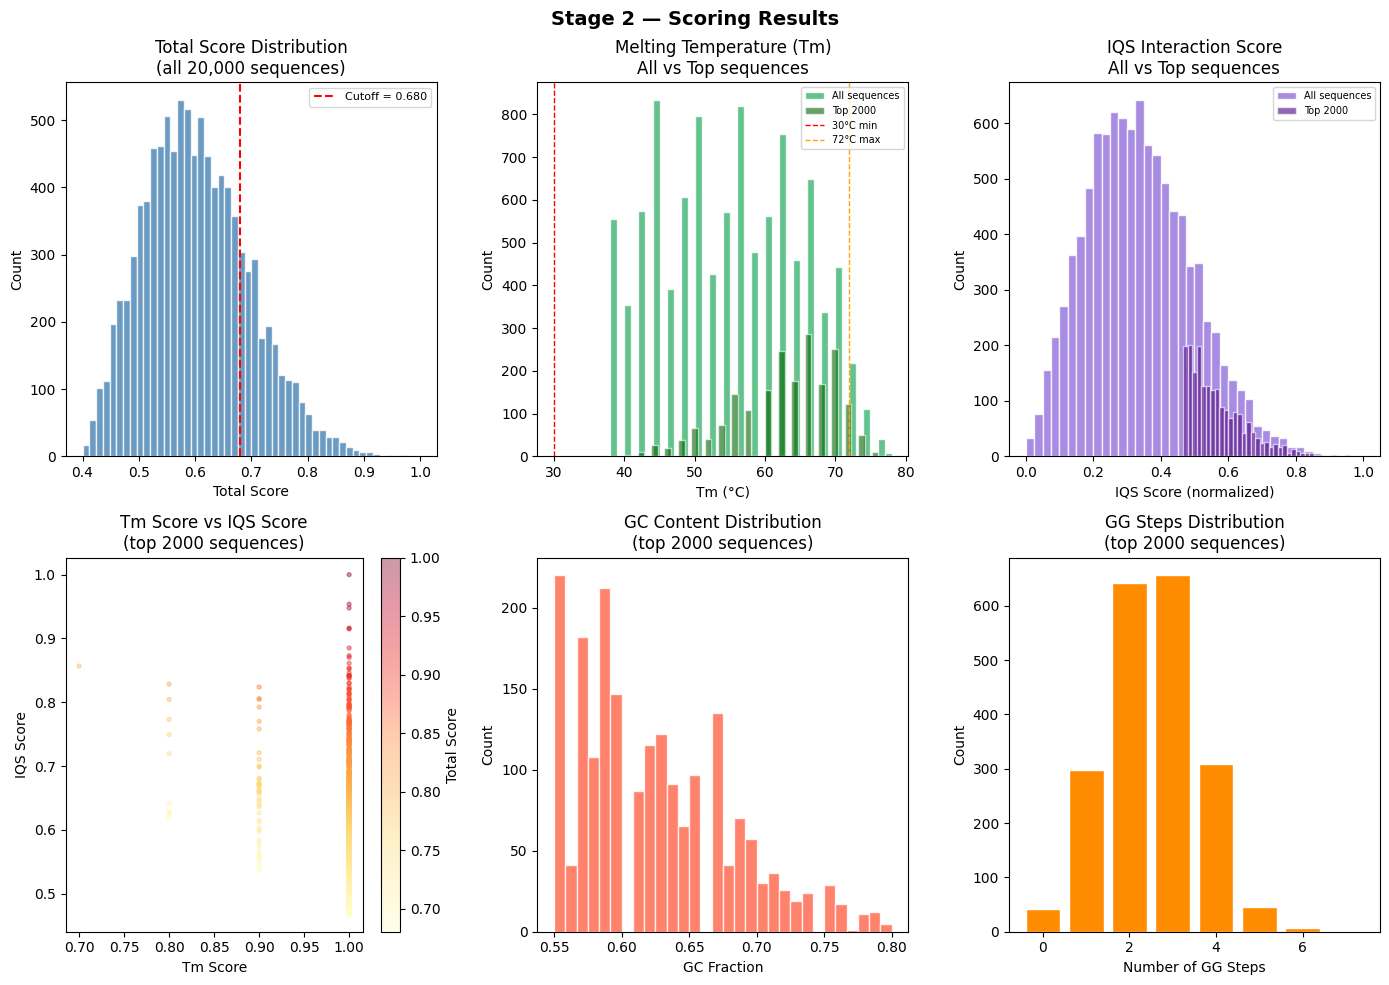

Plot saved to: generated_sequences\stage2_scoring_plots.png


In [9]:
fig = plt.figure(figsize=(14, 10))
fig.suptitle('Stage 2 — Scoring Results', fontsize=14, fontweight='bold')
gs = gridspec.GridSpec(2, 3, figure=fig)

# ── Plot 1: Total score distribution (all sequences) ──────────
ax1 = fig.add_subplot(gs[0, 0])
ax1.hist(df['total_score'], bins=50, color='steelblue', edgecolor='white', alpha=0.8)
ax1.axvline(cutoff_score, color='red', linestyle='--', linewidth=1.5,
            label=f'Cutoff = {cutoff_score:.3f}')
ax1.set_title('Total Score Distribution\n(all 20,000 sequences)')
ax1.set_xlabel('Total Score')
ax1.set_ylabel('Count')
ax1.legend(fontsize=8)

# ── Plot 2: Tm score distribution ─────────────────────────────
ax2 = fig.add_subplot(gs[0, 1])
ax2.hist(df['tm_celsius'], bins=40, color='mediumseagreen', edgecolor='white', alpha=0.8,
         label='All sequences')
ax2.hist(df_top['tm_celsius'], bins=40, color='darkgreen', edgecolor='white', alpha=0.6,
         label=f'Top {TOP_N}')
ax2.axvline(TM_OPTIMAL_MIN, color='red',    linestyle='--', linewidth=1, label=f'{TM_OPTIMAL_MIN}°C min')
ax2.axvline(TM_OPTIMAL_MAX, color='orange', linestyle='--', linewidth=1, label=f'{TM_OPTIMAL_MAX}°C max')
ax2.set_title('Melting Temperature (Tm)\nAll vs Top sequences')
ax2.set_xlabel('Tm (°C)')
ax2.set_ylabel('Count')
ax2.legend(fontsize=7)

# ── Plot 3: IQS score distribution ────────────────────────────
ax3 = fig.add_subplot(gs[0, 2])
ax3.hist(df['score_iqs'], bins=40, color='mediumpurple', edgecolor='white', alpha=0.8,
         label='All sequences')
ax3.hist(df_top['score_iqs'], bins=40, color='indigo', edgecolor='white', alpha=0.6,
         label=f'Top {TOP_N}')
ax3.set_title('IQS Interaction Score\nAll vs Top sequences')
ax3.set_xlabel('IQS Score (normalized)')
ax3.set_ylabel('Count')
ax3.legend(fontsize=7)

# ── Plot 4: Tm score vs IQS score (scatter, top sequences) ────
ax4 = fig.add_subplot(gs[1, 0])
sc = ax4.scatter(df_top['score_tm'], df_top['score_iqs'],
                 c=df_top['total_score'], cmap='YlOrRd',
                 alpha=0.4, s=8)
plt.colorbar(sc, ax=ax4, label='Total Score')
ax4.set_title(f'Tm Score vs IQS Score\n(top {TOP_N} sequences)')
ax4.set_xlabel('Tm Score')
ax4.set_ylabel('IQS Score')

# ── Plot 5: GC content of top sequences ───────────────────────
ax5 = fig.add_subplot(gs[1, 1])
ax5.hist(df_top['gc_content'], bins=30, color='tomato', edgecolor='white', alpha=0.8)
ax5.set_title(f'GC Content Distribution\n(top {TOP_N} sequences)')
ax5.set_xlabel('GC Fraction')
ax5.set_ylabel('Count')

# ── Plot 6: GG steps distribution of top sequences ────────────
ax6 = fig.add_subplot(gs[1, 2])
gg_counts = df_top['gg_steps'].value_counts().sort_index()
ax6.bar(gg_counts.index, gg_counts.values, color='darkorange', edgecolor='white')
ax6.set_title(f'GG Steps Distribution\n(top {TOP_N} sequences)')
ax6.set_xlabel('Number of GG Steps')
ax6.set_ylabel('Count')

plt.tight_layout()

# Save plot
plot_path = os.path.join("generated_sequences", 'stage2_scoring_plots.png')
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"Plot saved to: {plot_path}")

## Cell 10 — Score Sensitivity Check

This cell lets you quickly see what happens if you change the weights or TOP_N.  
Useful for checking if your top candidates are robust to weight changes.  
**No need to re-run the whole notebook — just run this cell.**

In [10]:
# ── Try different weight combinations and see how top 10 changes ──
weight_combos = [
    (0.40, 0.60, "Current (Tm=40%, IQS=60%)"),
    (0.30, 0.70, "IQS-heavy (Tm=30%, IQS=70%)"),
    (0.50, 0.50, "Equal weights (Tm=50%, IQS=50%)"),
]

print("Sensitivity check — top 10 sequence ranks under different weights:")
print()

for w_tm, w_iqs, label in weight_combos:
    df[f'test_score'] = w_tm * df['score_tm'] + w_iqs * df['score_iqs']
    top10 = df.nlargest(10, 'test_score')['sequence'].tolist()
    print(f"  {label}")
    for i, seq in enumerate(top10, 1):
        print(f"    {i:>2}. {seq}")
    print()

# Clean up temp column
df.drop(columns=['test_score'], inplace=True)

print("Note: If the top 10 sequences are largely the same across weight combinations,")
print("your results are robust. If they change a lot, consider adjusting weights in Cell 2.")

Sensitivity check — top 10 sequence ranks under different weights:

  Current (Tm=40%, IQS=60%)
     1. GGGTATGGAGACGGGAGGGTA
     2. CAACGGAAGGCCGGGAGGTTAG
     3. AGACGAGGGAGAACTCGGAAGC
     4. GACTATGAGGGAAGGAGCCGA
     5. GGAACGGGAGGTAGCTCTGGAG
     6. CCAGAAGATGGAGGGAAGTC
     7. CGGAAGGGTCATGAGCGAAGGA
     8. TGTGGTTCGGAGAGCGGGAAGT
     9. TTCCACGGGCTGGAGGGAAGC
    10. AGGAGCGGAACTGGGACCGG

  IQS-heavy (Tm=30%, IQS=70%)
     1. GGGTATGGAGACGGGAGGGTA
     2. CAACGGAAGGCCGGGAGGTTAG
     3. AGACGAGGGAGAACTCGGAAGC
     4. GACTATGAGGGAAGGAGCCGA
     5. GGAACGGGAGGTAGCTCTGGAG
     6. CCAGAAGATGGAGGGAAGTC
     7. CGGAAGGGTCATGAGCGAAGGA
     8. TGTGGTTCGGAGAGCGGGAAGT
     9. TTCCACGGGCTGGAGGGAAGC
    10. AGGAGCGGAACTGGGACCGG

  Equal weights (Tm=50%, IQS=50%)
     1. GGGTATGGAGACGGGAGGGTA
     2. CAACGGAAGGCCGGGAGGTTAG
     3. AGACGAGGGAGAACTCGGAAGC
     4. GACTATGAGGGAAGGAGCCGA
     5. GGAACGGGAGGTAGCTCTGGAG
     6. CCAGAAGATGGAGGGAAGTC
     7. CGGAAGGGTCATGAGCGAAGGA
     8. TGTGGTTCGGA

## Cell 11 — What's Next

Stage 2 is complete. Your output files are in `./generated_sequences/`:
- `stage2_filtered.csv` — top sequences with all scores
- `stage2_scoring_plots.png` — scoring distribution plots

**➡ Next: Open `03_sequence_filtering.ipynb` for Stage 3**  
Stage 3 applies a SantaLucia ΔG filter and then a diversity filter,  
reducing the 2,000 sequences to 500, then taking the top 100  
for AutoDock Vina docking. Stage 3 is pure Python; no 3D structures are built there.

In [11]:
print("Stage 2 complete.")
print(f"Output saved to  : {OUTPUT_FILE}")
print(f"Sequences kept   : {len(df_top)} (from {len(df)} input)")
print(f"Top sequence     : {df_top.iloc[0]['sequence']}")
print(f"  Tm             : {df_top.iloc[0]['tm_celsius']}°C")
print(f"  IQS score      : {df_top.iloc[0]['score_iqs']:.4f}")
print(f"  Total score    : {df_top.iloc[0]['total_score']:.4f}")

Stage 2 complete.
Output saved to  : generated_sequences\stage2_filtered.csv
Sequences kept   : 2000 (from 10000 input)
Top sequence     : GGGTATGGAGACGGGAGGGTA
  Tm             : 68°C
  IQS score      : 1.0000
  Total score    : 1.0000
